In [2]:

from datasets import load_dataset
import pandas as pd

# Load the public customer support dataset
dataset = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

# Convert to Pandas
df = dataset["train"].to_pandas()

# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nSample records:")
display(df.head())

print("\nCategory distribution:")
print(df["category"].value_counts())


README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

Dataset shape: (26872, 5)

Columns:
['flags', 'instruction', 'category', 'intent', 'response']

Sample records:


,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...



Category distribution:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
CONTACT         1999
INVOICE         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


In [3]:

# Inspect all unique intents and their corresponding categories

intent_summary = (
    df.groupby(["category", "intent"])
      .size()
      .reset_index(name="count")
      .sort_values(["category", "count"], ascending=[True, False])
)

display(intent_summary.to_string(index=False))

print("\nTotal unique intents:", df["intent"].nunique())
print("\nMissing values:")
print(df.isnull().sum())


'    category                   intent  count\n     ACCOUNT             edit_account   1000\n     ACCOUNT           switch_account   1000\n     ACCOUNT    registration_problems    999\n     ACCOUNT           create_account    997\n     ACCOUNT           delete_account    995\n     ACCOUNT         recover_password    995\n      CANCEL   check_cancellation_fee    950\n     CONTACT contact_customer_service   1000\n     CONTACT      contact_human_agent    999\n    DELIVERY          delivery_period    999\n    DELIVERY         delivery_options    995\n    FEEDBACK                complaint   1000\n    FEEDBACK                   review    997\n     INVOICE            check_invoice   1000\n     INVOICE              get_invoice    999\n       ORDER             cancel_order    998\n       ORDER              place_order    998\n       ORDER             change_order    997\n       ORDER              track_order    995\n     PAYMENT    check_payment_methods    999\n     PAYMENT            payment_i


Total unique intents: 27

Missing values:
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64


In [4]:

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)

for category in sorted(df["category"].unique()):
    print(f"\n{'='*55}")
    print(f"CATEGORY: {category}")
    print("="*55)

    intents = sorted(df.loc[df["category"] == category, "intent"].unique())

    for intent in intents:
        print(intent)



CATEGORY: ACCOUNT
create_account
delete_account
edit_account
recover_password
registration_problems
switch_account

CATEGORY: CANCEL
check_cancellation_fee

CATEGORY: CONTACT
contact_customer_service
contact_human_agent

CATEGORY: DELIVERY
delivery_options
delivery_period

CATEGORY: FEEDBACK
complaint
review

CATEGORY: INVOICE
check_invoice
get_invoice

CATEGORY: ORDER
cancel_order
change_order
place_order
track_order

CATEGORY: PAYMENT
check_payment_methods
payment_issue

CATEGORY: REFUND
check_refund_policy
get_refund
track_refund

CATEGORY: SHIPPING
change_shipping_address
set_up_shipping_address

CATEGORY: SUBSCRIPTION
newsletter_subscription


In [7]:

intent_mapping = {
    "create_account": "Technical Support",
    "delete_account": "Technical Support",
    "edit_account": "Technical Support",
    "recover_password": "Technical Support",
    "registration_problems": "Technical Support",
    "switch_account": "Technical Support",

    "check_cancellation_fee": "Refund & Cancellation",

    "contact_customer_service": "General Inquiry",
    "contact_human_agent": "General Inquiry",

    "delivery_options": "Order Status",
    "delivery_period": "Order Status",

    "complaint": "General Inquiry",
    "review": "General Inquiry",

    "check_invoice": "General Inquiry",
    "get_invoice": "General Inquiry",

    "cancel_order": "Refund & Cancellation",
    "change_order": "Order Status",
    "place_order": "Order Status",
    "track_order": "Order Status",

    "check_payment_methods": "General Inquiry",
    "payment_issue": "Technical Support",

    "check_refund_policy": "Refund & Cancellation",
    "get_refund": "Refund & Cancellation",
    "track_refund": "Refund & Cancellation",

    "change_shipping_address": "Order Status",
    "set_up_shipping_address": "Order Status",

    "newsletter_subscription": "General Inquiry"
}

# Verify every intent has a mapping
unmapped = set(df["intent"].unique()) - set(intent_mapping.keys())

print("Unmapped intents:", unmapped)
print("Total mapped intents:", len(intent_mapping))


Unmapped intents: set()
Total mapped intents: 27


In [9]:
# Create a copy
df_model = df.copy()

# Map original intents to five target categories
df_model["target_category"] = df_model["intent"].map(intent_mapping)

# Keep only the required columns (excluding the original 'category' column)
df_model = df_model[
    ["instruction", "target_category", "intent"]
].copy()

# Rename columns
df_model.rename(columns={
    "instruction": "query",
    "target_category": "category"
}, inplace=True)

print("Dataset shape:", df_model.shape)
print("\nNew category distribution:")
print(df_model["category"].value_counts())

display(df_model.head())

Dataset shape: (26872, 3)

New category distribution:
category
General Inquiry          7993
Technical Support        6985
Order Status             6954
Refund & Cancellation    4940
Name: count, dtype: int64


,query,category,intent
0,question about cancelling order {{Order Number}},Refund & Cancellation,cancel_order
1,i have a question about cancelling oorder {{Order Number}},Refund & Cancellation,cancel_order
2,i need help cancelling puchase {{Order Number}},Refund & Cancellation,cancel_order
3,I need to cancel purchase {{Order Number}},Refund & Cancellation,cancel_order
4,"I cannot afford this order, cancel purchase {{Order Number}}",Refund & Cancellation,cancel_order


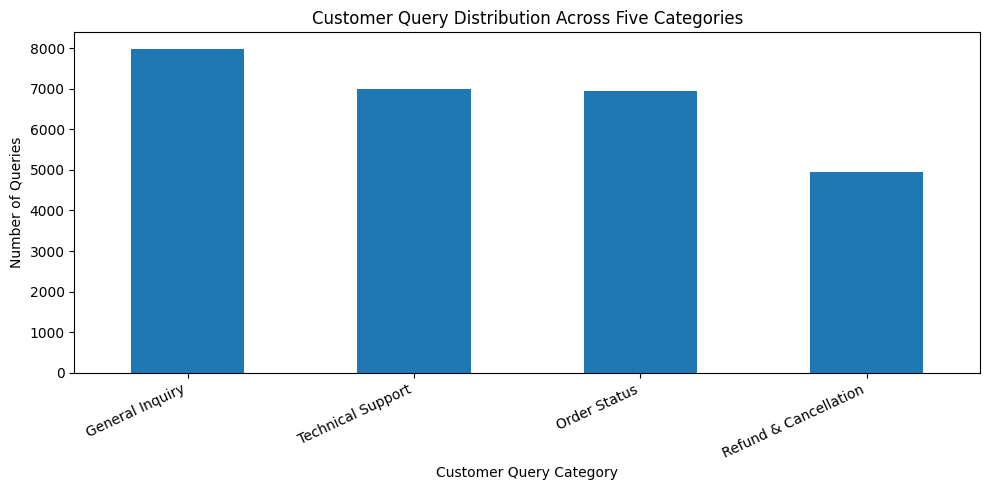

In [10]:

import matplotlib.pyplot as plt

class_counts = df_model["category"].value_counts()

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")
plt.title("Customer Query Distribution Across Five Categories")
plt.xlabel("Customer Query Category")
plt.ylabel("Number of Queries")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


In [16]:

import random
import pandas as pd

random.seed(42)

# 1. Product list
products = [
    "laptop", "smartphone", "wireless headphones",
    "smartwatch", "tablet", "keyboard", "mouse",
    "monitor", "printer", "Bluetooth speaker",
    "camera", "power bank", "gaming console",
    "router", "external hard drive", "mechanical keyboard",
    "gaming laptop", "fitness tracker", "webcam",
    "portable SSD", "projector", "microphone",
    "graphics tablet", "wireless charger", "smart TV"
]

# 2. Diverse customer query templates
templates = [
    "What are the features of the {}?",
    "Can you tell me the specifications of the {}?",
    "How much does the {} cost?",
    "Is the {} currently available?",
    "What is special about the {}?",
    "Does the {} support wireless connectivity?",
    "Can you explain the technical details of the {}?",
    "What warranty is provided with the {}?",
    "Is the {} compatible with other devices?",
    "Would you recommend the {}?",
    "What are the advantages of buying the {}?",
    "Tell me more about the {}.",
    "I want to know the price of the {}.",
    "Does the {} come with accessories?",
    "What versions of the {} are available?",
    "How does the {} work?",
    "What makes the {} different from other products?",
    "Can I get more information about the {}?",
    "Is the {} suitable for everyday use?",
    "What is the battery life of the {}?",
    "Does the {} come with a manufacturer's warranty?",
    "Are there different models of the {}?",
    "What colors are available for the {}?",
    "Can you explain how to use the {}?",
    "Is the {} suitable for professional use?",
    "What are the main specifications of this {}?",
    "I am interested in purchasing a {}. What should I know?",
    "Does this {} have any additional features?",
    "Can you tell me whether the {} supports Bluetooth?",
    "What is included in the box with the {}?",
    "Is there a newer version of the {}?",
    "How reliable is the {}?",
    "What are the technical requirements for the {}?",
    "Can I use the {} with my existing devices?",
    "Does the {} support fast charging?",
    "What storage options are available for the {}?",
    "Is the {} available in different sizes?",
    "Can you provide details about the build quality of the {}?",
    "What is the expected lifespan of the {}?",
    "Does the {} support the latest software?",
    "I want to compare the available models of the {}.",
    "What should I consider before buying a {}?",
    "Can you explain the performance of the {}?",
    "Does the {} have any special connectivity options?",
    "What is the difference between the basic and premium {}?",
    "Is the {} a good choice for students?",
    "Can you tell me about the design of the {}?",
    "What are the available configurations of the {}?",
    "Does the {} include installation support?",
    "Where can I find detailed information about the {}?"
]

# 3. Generate product-query combinations
all_queries = []

for product in products:
    for template in templates:
        query = template.format(product)

        all_queries.append({
            "query": query,
            "category": "Product Inquiry",
            "intent": "product_inquiry"
        })

# 4. Randomly select 1000 unique queries
product_df = pd.DataFrame(all_queries)

product_df.drop_duplicates(
    subset=["query"],
    inplace=True
)

product_df = product_df.sample(
    n=1000,
    random_state=42
).reset_index(drop=True)

# 5. Inspect generated data
print("Synthetic product queries:", len(product_df))
print("\nUnique queries:", product_df["query"].nunique())

display(product_df.head())


Synthetic product queries: 1000

Unique queries: 1000


,query,category,intent
0,Is there a newer version of the router?,Product Inquiry,product_inquiry
1,How much does the graphics tablet cost?,Product Inquiry,product_inquiry
2,What is the difference between the basic and premium monitor?,Product Inquiry,product_inquiry
3,Is there a newer version of the webcam?,Product Inquiry,product_inquiry
4,What are the available configurations of the Bluetooth speaker?,Product Inquiry,product_inquiry


In [17]:

# Combine original and synthetic datasets
final_df = pd.concat(
    [df_model, product_df],
    ignore_index=True
)

# Remove exact duplicate queries
final_df.drop_duplicates(
    subset=["query"],
    inplace=True
)

# Remove missing records
final_df.dropna(subset=["query", "category"], inplace=True)

# Reset index
final_df.reset_index(drop=True, inplace=True)

print("Final dataset shape:", final_df.shape)

print("\nFinal category distribution:")
print(final_df["category"].value_counts())

print("\nNumber of classes:", final_df["category"].nunique())


Final dataset shape: (25635, 3)

Final category distribution:
category
General Inquiry          7824
Technical Support        6442
Order Status             6304
Refund & Cancellation    4065
Product Inquiry          1000
Name: count, dtype: int64

Number of classes: 5


In [18]:

# Check duplicate queries in the original dataset
duplicate_count = df_model["query"].duplicated().sum()

# Check whether identical queries have conflicting labels
conflicts = (
    df_model.groupby("query")["category"]
    .nunique()
)

conflicting_queries = conflicts[conflicts > 1]

print("Original records:", len(df_model))
print("Duplicate queries:", duplicate_count)
print("Queries with conflicting labels:", len(conflicting_queries))

# Display conflicting examples
if len(conflicting_queries) > 0:
    conflict_data = df_model[
        df_model["query"].isin(conflicting_queries.index)
    ]

    display(conflict_data.head(20))


Original records: 26872
Duplicate queries: 2237
Queries with conflicting labels: 0


In [19]:

# Prepare original data
original_data = df_model.copy()

original_data["source"] = "Bitext"

# Prepare synthetic data
synthetic_data = product_df.copy()

synthetic_data["source"] = "Synthetic"

# Combine
final_df = pd.concat(
    [original_data, synthetic_data],
    ignore_index=True
)

# Remove exact duplicate queries
final_df.drop_duplicates(
    subset=["query"],
    keep="first",
    inplace=True
)

final_df.reset_index(drop=True, inplace=True)

# Dataset summary
print("Final dataset:", final_df.shape)

print("\nCategory distribution:")
display(final_df["category"].value_counts())

print("\nData source distribution:")
display(final_df["source"].value_counts())

print("\nCategory and source distribution:")
display(pd.crosstab(final_df["category"], final_df["source"]))


Final dataset: (25635, 4)

Category distribution:


,count
category,
General Inquiry,7824
Technical Support,6442
Order Status,6304
Refund & Cancellation,4065
Product Inquiry,1000



Data source distribution:


,count
source,
Bitext,24635
Synthetic,1000



Category and source distribution:


source,Bitext,Synthetic
category,,
General Inquiry,7824,0
Order Status,6304,0
Product Inquiry,0,1000
Refund & Cancellation,4065,0
Technical Support,6442,0


In [20]:
final_df.to_csv(
    "customer_support_dataset.csv",
    index=False
)

print("Dataset exported successfully!")

Dataset exported successfully!
